In [1]:
from pathlib import Path
import sys

from matplotlib.pyplot import annotate

ROOT = Path.cwd().parent
sys.path.insert(0, str(ROOT))

# print(Path.cwd(), ROOT)

In [2]:
from services.ingester_prepper import IngesterPrepper

svc = IngesterPrepper()
_ = svc.load_option_chain()
df = svc.process_option_chain()
df

QUOTE_READTIME,QUOTE_DATE,UNDERLYING_LAST,EXPIRE_DATE,DTE,C_BID,C_ASK,STRIKE,P_BID,P_ASK
datetime[μs],date,f64,date,i64,f64,f64,f64,f64,f64
2021-11-01 16:00:00,2021-11-01,258.34,2021-11-05,4,158.15,158.65,100.0,0.0,0.02
2021-11-01 16:00:00,2021-11-01,258.34,2021-11-05,4,153.15,153.65,105.0,0.0,0.02
2021-11-01 16:00:00,2021-11-01,258.34,2021-11-05,4,148.15,148.65,110.0,0.0,0.02
2021-11-01 16:00:00,2021-11-01,258.34,2021-11-05,4,142.4,143.95,115.0,0.0,0.02
2021-11-01 16:00:00,2021-11-01,258.34,2021-11-05,4,137.4,138.95,120.0,0.0,0.01
…,…,…,…,…,…,…,…,…,…
2021-08-31 16:00:00,2021-08-31,223.76,2023-06-16,654,16.05,18.45,350.0,134.55,143.8
2021-08-31 16:00:00,2021-08-31,223.76,2023-06-16,654,11.25,18.4,362.5,145.55,154.85
2021-08-31 16:00:00,2021-08-31,223.76,2023-06-16,654,11.15,18.4,375.0,156.65,165.75


In [3]:
import polars as pl

entry_date = df.select(
    pl.col("QUOTE_DATE")
).unique().sort("QUOTE_DATE")[0].item()  # first quote data in the data

entry_date

datetime.date(2020, 1, 2)

In [4]:
available_expiry_dates = df.filter(
    pl.col("QUOTE_DATE") == entry_date
)["EXPIRE_DATE"].unique()

available_expiry_dates

EXPIRE_DATE
date
2020-01-03
2020-01-10
2020-01-17
2020-01-24
2020-01-31
…
2020-03-20
2020-06-19
2021-01-15


In [5]:
chosen_expiry = available_expiry_dates.sort()[-1]
chosen_expiry

datetime.date(2022, 1, 21)

In [6]:
# xs: short for cross-section, or for expiry-speculation
xs = df.filter(
    (pl.col("QUOTE_DATE") == entry_date)
    & (pl.col("EXPIRE_DATE") == chosen_expiry)
)

xs

QUOTE_READTIME,QUOTE_DATE,UNDERLYING_LAST,EXPIRE_DATE,DTE,C_BID,C_ASK,STRIKE,P_BID,P_ASK
datetime[μs],date,f64,date,i64,f64,f64,f64,f64,f64
2020-01-02 16:00:00,2020-01-02,239.86,2022-01-21,750,153.15,157.4,90.0,1.77,3.15
2020-01-02 16:00:00,2020-01-02,239.86,2022-01-21,750,148.5,153.0,95.0,1.43,3.65
2020-01-02 16:00:00,2020-01-02,239.86,2022-01-21,750,144.0,148.6,100.0,1.76,3.1
2020-01-02 16:00:00,2020-01-02,239.86,2022-01-21,750,139.5,144.4,105.0,2.13,4.85
2020-01-02 16:00:00,2020-01-02,239.86,2022-01-21,750,135.5,140.2,110.0,2.57,4.7
…,…,…,…,…,…,…,…,…,…
2020-01-02 16:00:00,2020-01-02,239.86,2022-01-21,750,24.4,28.5,315.0,90.15,94.0
2020-01-02 16:00:00,2020-01-02,239.86,2022-01-21,750,23.2,27.05,320.0,94.05,97.75
2020-01-02 16:00:00,2020-01-02,239.86,2022-01-21,750,20.95,24.8,330.0,101.65,105.45


In [7]:
# because we filtered based on a specified QUOTE_DATE & EXPIRE_DATE
assert len(xs['QUOTE_DATE'].unique()) == 1
assert len(xs['EXPIRE_DATE'].unique()) == 1
assert len(xs['DTE'].unique()) == 1

In [8]:
%matplotlib inline

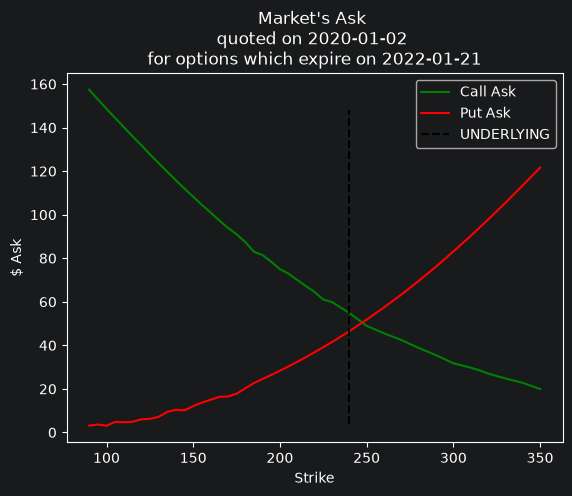

In [9]:
import matplotlib.pyplot as plt


def plot_ask_quotes(xs):
    # fig, ax = plt.subplots()

    plt.plot(xs['STRIKE'], xs['C_ASK'], '-g', label="Call Ask")
    plt.plot(xs['STRIKE'], xs['P_ASK'], '-r', label="Put Ask")
    plt.axvline(x=xs['UNDERLYING_LAST'][0], ymin=0.05, ymax=0.9, color='k', linestyle='--', label="UNDERLYING")

    plt.legend()

    plt.xlabel("Strike")
    plt.ylabel("$ Ask")

plot_ask_quotes(xs)
plt.title(f"Market's Ask \nquoted on {entry_date} \nfor options which expire on {chosen_expiry}")
plt.show()

''

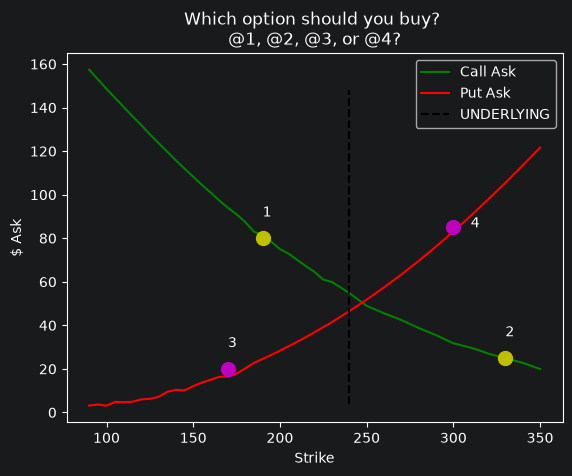

In [10]:
plot_ask_quotes(xs)

def plot_markers(data):
    # data is a list of dict
    # each dict contains x,y, marker fmt string, text, and relative_orientation
    for d in data:
        x, y = d.get('x'), d.get('y')
        fmt = d.get('fmt')
        size = d.get('size')
        plt.plot([x], [y], fmt, markersize=size)

        txt = d.get('txt')
        rp = d.get('rp')  # relative position # up down right left
        if 'u' in rp:
            y += 10
        if 'd' in rp:
            y -= 10
        if 'r' in rp:
            x += 10
        if 'l' in rp:
            x -= 10
        plt.annotate(txt, (x, y))

markers = [
    dict(x=190, y=80, fmt='oy', size=10, txt='1', rp='u'),
    dict(x=330, y=25, fmt='oy', size=10, txt='2', rp='u'),
    dict(x=170, y=20, fmt='om', size=10, txt='3', rp='u'),
    dict(x=300, y=85, fmt='om', size=10, txt='4', rp='r'),
]
plot_markers(markers)

plt.title(f'Which option should you buy? \n@1, @2, @3, or @4?',)
;

In [11]:
xs = xs.with_columns(
    (pl.col("C_ASK") + pl.col("P_ASK")).alias("PAIR_ASK"),
    (pl.col("C_BID") + pl.col("P_BID")).alias("PAIR_BID"),
)

xs

QUOTE_READTIME,QUOTE_DATE,UNDERLYING_LAST,EXPIRE_DATE,DTE,C_BID,C_ASK,STRIKE,P_BID,P_ASK,PAIR_ASK,PAIR_BID
datetime[μs],date,f64,date,i64,f64,f64,f64,f64,f64,f64,f64
2020-01-02 16:00:00,2020-01-02,239.86,2022-01-21,750,153.15,157.4,90.0,1.77,3.15,160.55,154.92
2020-01-02 16:00:00,2020-01-02,239.86,2022-01-21,750,148.5,153.0,95.0,1.43,3.65,156.65,149.93
2020-01-02 16:00:00,2020-01-02,239.86,2022-01-21,750,144.0,148.6,100.0,1.76,3.1,151.7,145.76
2020-01-02 16:00:00,2020-01-02,239.86,2022-01-21,750,139.5,144.4,105.0,2.13,4.85,149.25,141.63
2020-01-02 16:00:00,2020-01-02,239.86,2022-01-21,750,135.5,140.2,110.0,2.57,4.7,144.9,138.07
…,…,…,…,…,…,…,…,…,…,…,…
2020-01-02 16:00:00,2020-01-02,239.86,2022-01-21,750,24.4,28.5,315.0,90.15,94.0,122.5,114.55
2020-01-02 16:00:00,2020-01-02,239.86,2022-01-21,750,23.2,27.05,320.0,94.05,97.75,124.8,117.25
2020-01-02 16:00:00,2020-01-02,239.86,2022-01-21,750,20.95,24.8,330.0,101.65,105.45,130.25,122.6


Text(0.5, 1.0, 'Oct Entry \non 2020-01-02 \nfor options which expire on 2022-01-21')

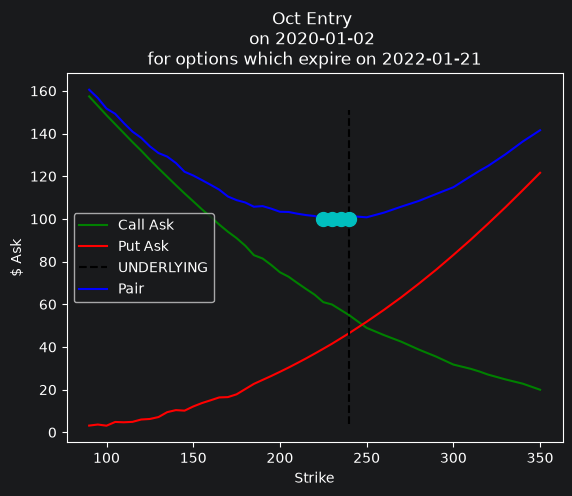

In [12]:
plot_ask_quotes(xs)

def plot_pair(xs, fmt='-b'):
    # ignoring bid-ask spread only for plotting/illustration
    # bid-ask spread not ignored in decision/move/analysis
    plt.plot(xs['STRIKE'], xs['PAIR_ASK'], fmt, label="Pair")

    plt.legend()

    plt.xlabel("Strike")
    plt.ylabel("$ Ask")

plot_pair(xs)

markers = [
    dict(x=225, y=100, fmt='oc', size=10, txt='', rp='u'),
    dict(x=230, y=100, fmt='oc', size=10, txt='', rp='u'),
    dict(x=235, y=100, fmt='oc', size=10, txt='', rp='u'),
    dict(x=240, y=100, fmt='oc', size=10, txt='', rp='u'),
]
plot_markers(markers)
plt.title(f"Oct Entry \non {entry_date} \nfor options which expire on {chosen_expiry}")

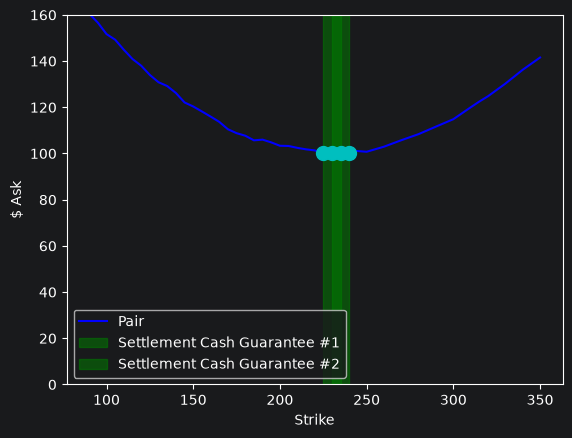

In [13]:
# settlement guarantee
markers.sort(key=lambda d: d.get('x'))
pair_strikes = [d.get('x') for d in markers]

def plot_settlement_guarantee(pair_strikes):
    s0, s1, s2, s3 = pair_strikes
    plt.axvspan(xmin=s0, xmax=s3, color='g', alpha=0.5, label="Settlement Cash Guarantee #1")
    plt.axvspan(xmin=s1, xmax=s2, color='g', alpha=0.5, label="Settlement Cash Guarantee #2")
    plt.legend()

# plot_pair(xs, '--c')
plot_pair(xs)
plot_markers(markers)

plt.ylim(0, 160)

plot_settlement_guarantee(pair_strikes)

In [14]:
# quote dates for same expiry over time
quote_dates = df.filter(
    (pl.col("EXPIRE_DATE") == chosen_expiry)
)["QUOTE_DATE"].unique().sort()

quote_dates

QUOTE_DATE
date
2020-01-02
2020-01-03
2020-01-06
2020-01-07
2020-01-08
…
2022-01-17
2022-01-18
2022-01-19


In [15]:
quote_date = quote_dates[100]  # sometime later
xs_100 = df.filter(
    (pl.col("QUOTE_DATE") == quote_date)
    & (pl.col("EXPIRE_DATE") == chosen_expiry)
)

xs_100 = xs_100.with_columns(
    (pl.col("C_ASK") + pl.col("P_ASK")).alias("PAIR_ASK"),
    (pl.col("C_BID") + pl.col("P_BID")).alias("PAIR_BID"),
)

xs_100

QUOTE_READTIME,QUOTE_DATE,UNDERLYING_LAST,EXPIRE_DATE,DTE,C_BID,C_ASK,STRIKE,P_BID,P_ASK,PAIR_ASK,PAIR_BID
datetime[μs],date,f64,date,i64,f64,f64,f64,f64,f64,f64,f64
2020-05-27 16:00:00,2020-05-27,341.14,2022-01-21,604,251.0,255.8,90.0,1.28,2.8,258.6,252.28
2020-05-27 16:00:00,2020-05-27,341.14,2022-01-21,604,246.5,251.4,95.0,0.99,4.85,256.25,247.49
2020-05-27 16:00:00,2020-05-27,341.14,2022-01-21,604,242.0,246.5,100.0,2.5,5.4,251.9,244.5
2020-05-27 16:00:00,2020-05-27,341.14,2022-01-21,604,237.5,242.0,105.0,1.55,6.05,248.05,239.05
2020-05-27 16:00:00,2020-05-27,341.14,2022-01-21,604,233.1,238.0,110.0,2.05,6.7,244.7,235.15
…,…,…,…,…,…,…,…,…,…,…,…
2020-05-27 16:00:00,2020-05-27,341.14,2022-01-21,604,31.3,34.65,490.0,176.5,181.4,216.05,207.8
2020-05-27 16:00:00,2020-05-27,341.14,2022-01-21,604,28.9,32.6,500.0,185.0,189.4,222.0,213.9
2020-05-27 16:00:00,2020-05-27,341.14,2022-01-21,604,27.35,30.7,510.0,192.5,197.4,228.1,219.85


''

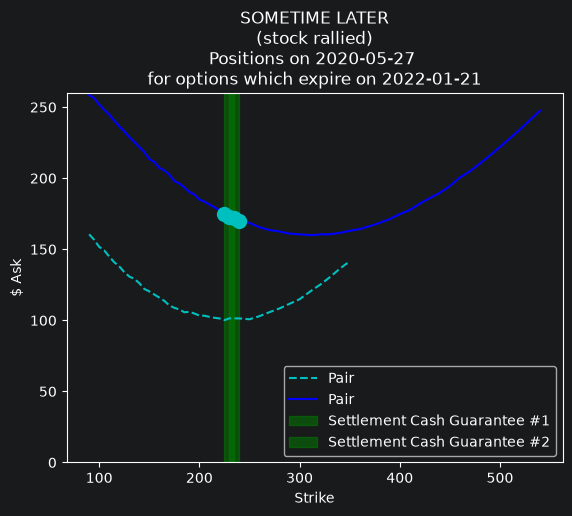

In [16]:
plot_pair(xs, '--c')  # some time ago/@entry
plot_pair(xs_100)

plt.ylim(0, 260)


markers = [
    dict(x=225, y=175, fmt='oc', size=10, txt='', rp='u'),
    dict(x=230, y=173, fmt='oc', size=10, txt='', rp='u'),
    dict(x=235, y=172, fmt='oc', size=10, txt='', rp='u'),
    dict(x=240, y=170, fmt='oc', size=10, txt='', rp='u'),
]
plot_markers(markers)
plt.title(f"SOMETIME LATER\n(stock rallied)\nPositions on {quote_date} \nfor options which expire on {chosen_expiry}")


plot_settlement_guarantee(pair_strikes)
;

''

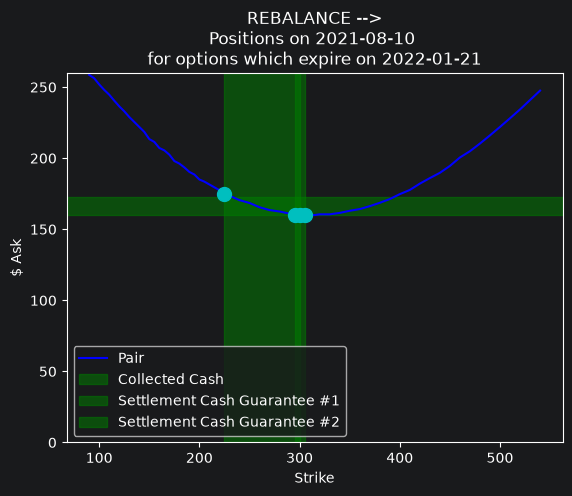

In [19]:
pair_strikes = [225, 295, 300, 305]

plot_pair(xs_100)
plt.ylim(0, 260)
markers = [
    dict(x=225, y=175, fmt='oc', size=10, txt='', rp='u'),
    dict(x=295, y=160, fmt='oc', size=10, txt='', rp='u'),
    dict(x=300, y=160, fmt='oc', size=10, txt='', rp='u'),
    dict(x=305, y=160, fmt='oc', size=10, txt='', rp='u'),
]
plot_markers(markers)
plt.title(f"REBALANCE -->\nPositions on {quote_date} \nfor options which expire on {chosen_expiry}")

def plot_collected_cash(high, low):
    plt.axhspan(ymin=low, ymax=high, color='g', alpha=0.5, label="Collected Cash")

plot_collected_cash(173, 160)

plot_settlement_guarantee(pair_strikes)
;

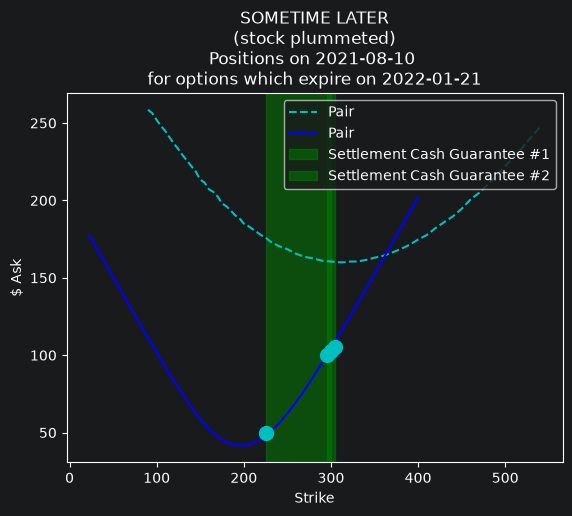

In [22]:
quote_date = quote_dates[400]  # sometime later
xs_400 = df.filter(
    (pl.col("QUOTE_DATE") == quote_date)
    & (pl.col("EXPIRE_DATE") == chosen_expiry)
)

xs_400 = xs_400.with_columns(
    (pl.col("C_ASK") + pl.col("P_ASK")).alias("PAIR_ASK"),
    (pl.col("C_BID") + pl.col("P_BID")).alias("PAIR_BID"),
)

plot_pair(xs_100, '--c')  # some time ago/@entry
plot_pair(xs_400)

markers = [
    dict(x=225, y=50, fmt='oc', size=10, txt='', rp='u'),
    dict(x=295, y=100, fmt='oc', size=10, txt='', rp='u'),
    dict(x=300, y=103, fmt='oc', size=10, txt='', rp='u'),
    dict(x=305, y=105, fmt='oc', size=10, txt='', rp='u'),
]

plot_markers(markers)
plt.title(f"SOMETIME LATER\n(stock plummeted)\nPositions on {quote_date} \nfor options which expire on {chosen_expiry}")


plot_settlement_guarantee(pair_strikes)


''

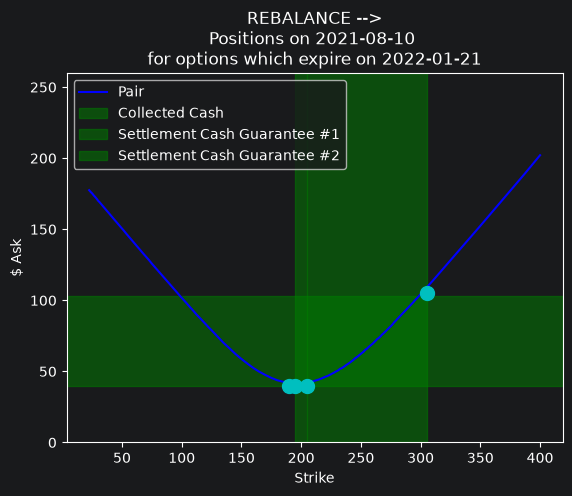

In [26]:
pair_strikes = [195, 205, 205, 305]

plot_pair(xs_400)
plt.ylim(0, 260)
markers = [
    dict(x=190, y=40, fmt='oc', size=10, txt='', rp='u'),
    dict(x=195, y=40, fmt='oc', size=10, txt='', rp='u'),
    dict(x=205, y=40, fmt='oc', size=10, txt='', rp='u'),
    dict(x=305, y=105, fmt='oc', size=10, txt='', rp='u'),
]
plot_markers(markers)
plt.title(f"REBALANCE -->\nPositions on {quote_date} \nfor options which expire on {chosen_expiry}")

plot_collected_cash(103, 40)
plot_settlement_guarantee(pair_strikes)
;